In [5]:
import os

# set the environment variable to control the number of threads
# NEEDS TO BE DONE BEFORE CCL IS IMPORTED
original_omp_num_threads = os.environ.get('OMP_NUM_THREADS', None)
os.environ['OMP_NUM_THREADS'] = '1'

import pyccl as ccl
import time
import tqdm
import numpy as np
import matplotlib.pyplot as plt

import src.simulate as sim

Text(0, 0.5, 'N(z)')

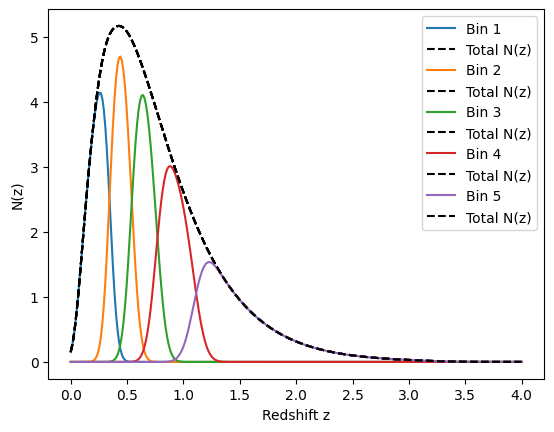

In [15]:
def build_nz_bins(sigma_z, n_bins=5):
    """Build redshift bins and convolve with photo-z errors."""
    # Construct the redshift distribution
    z = np.linspace(0.05, 3.5, 300)

    # Bin the redshift distribution with equal area per bin
    kwargs = {'z0': 0.13, 'alpha': 0.78}
    z_bins, dndz_bins = sim.bin_dndz(n_bins, z, sim.Smail_dndz, **kwargs)

    # Convolve photo-z errors
    dndz_bin_ph = np.zeros((n_bins, len(z)))
    for j in range(n_bins):
        z_ph, dndz_bin_ph[j] = sim.convolve_photoz(
            sigma=sigma_z, 
            zs=z_bins[j], 
            dndz_spec=dndz_bins[j]
        )

    return z_ph, dndz_bin_ph

n_bins=5
z_ph, dndz_bin_ph = build_nz_bins(sigma_z=0.04, n_bins=n_bins)

for j in range(n_bins):
    plt.plot(
        z_ph, 
        dndz_bin_ph[j], 
        label=f'Bin {j+1}'
    )
    plt.plot(
        z_ph,
        np.sum(dndz_bin_ph, axis=0),
        color='k',
        label='Total N(z)',
        ls='--'
    )
plt.legend()
plt.xlabel('Redshift z')
plt.ylabel('N(z)')

In [16]:
n = 100
boltz_avg_time = 0.0
proj_avg_time = 0.0
for _ in tqdm.trange(n):
    # Vary cosmology each time to force a cold start of the Boltzmann solver
    cosmo = ccl.Cosmology(
        Omega_c=np.random.uniform(0.17, 0.4),
        Omega_b=np.random.uniform(0.03, 0.07),
        h=np.random.uniform(0.4, 1.1),
        n_s=np.random.uniform(0.8, 1.1),
        sigma8=np.random.uniform(0.65, 1.0),
        matter_power_spectrum='halofit'
    )

    # Time the Boltzmann solver (non-linear power spectrum computation)
    start = time.perf_counter() # Start timing the Boltzmann solver
    nonlin_pow = cosmo.get_nonlin_power() # This will trigger the Boltzmann solver if the cosmology has changed
    end = time.perf_counter() # End timing the Boltzmann solver
    boltz_avg_time += (end - start)

    # Define multipoles
    ells = np.geomspace(2, 5000, 50)

    n_bins = dndz_bin_ph.shape[0]
    inds = list(zip(*np.tril_indices(n_bins)))
    c_ells = np.empty((len(inds), len(ells)))

    # Time the projection with the non-linear power spectrum
    start = time.perf_counter() # Start timing the projection
    for i, arg in enumerate(inds):
        j, k = arg
        tracer1 = ccl.WeakLensingTracer(cosmo, dndz=(z_ph, dndz_bin_ph[j]))
        tracer2 = ccl.WeakLensingTracer(cosmo, dndz=(z_ph, dndz_bin_ph[k]))
        c_ells[i,:] = ccl.angular_cl(cosmo, tracer1, tracer2, ells, p_of_k_a=nonlin_pow)

        # Test for 3x2pt consistency
        # _ = ccl.angular_cl(cosmo, tracer1, tracer2, ells, p_of_k_a=nonlin_pow)
        # _ = ccl.angular_cl(cosmo, tracer1, tracer2, ells, p_of_k_a=nonlin_pow)

    end = time.perf_counter() # End timing the projection
    proj_avg_time += (end - start)

proj_avg_time /= n
boltz_avg_time /= n

print(f"Cold start Boltzmann solver avg time: {boltz_avg_time:.6f} seconds")
print(f"Cold start projection avg time: {proj_avg_time:.6f} seconds")

# Compute fraction of time spent in Boltzmann solver vs projection
total_time = boltz_avg_time + proj_avg_time
print(f"Fraction of time in Boltzmann solver: {boltz_avg_time / total_time:.2%}")
print(f"Fraction of time in projection: {proj_avg_time / total_time:.2%}")

100%|██████████| 100/100 [02:26<00:00,  1.47s/it]

Cold start Boltzmann solver avg time: 1.353175 seconds
Cold start projection avg time: 0.110758 seconds
Fraction of time in Boltzmann solver: 92.43%
Fraction of time in projection: 7.57%


In [4]:
# Compute time spent in projection
#proj_avg_time = total_time * 0.1441 # lowest observed projection time per iteration
total_mcmc_time = 1255 # CPU core hours
projection_time = total_mcmc_time * (proj_avg_time / total_time)
print(f"Estimated time spent in projection: {projection_time:.2f} CPU core hours")
print(f"Estimated time spent in Boltzmann solver: {total_mcmc_time - projection_time:.2f} CPU core hours")

Estimated time spent in projection: 189.89 CPU core hours
Estimated time spent in Boltzmann solver: 1065.11 CPU core hours


In [23]:
z = np.linspace(0.05, 3.5, 300)
dndz = sim.Smail_dndz(z, z0=0.13, alpha=0.78)
n = 100
boltz_avg_time = 0.0
proj_avg_time = 0.0
for _ in tqdm.trange(n):
    # Vary cosmology each time to force a cold start of the Boltzmann solver
    cosmo = ccl.Cosmology(
        Omega_c=np.random.uniform(0.2, 0.4),
        Omega_b=np.random.uniform(0.03, 0.06),
        h=np.random.uniform(0.6, 0.8),
        n_s=np.random.uniform(0.9, 1.0),
        sigma8=np.random.uniform(0.7, 0.9)
    )
    tracer = ccl.WeakLensingTracer(cosmo, dndz=(z, dndz))
    ells = np.geomspace(2, 5000, 50)

    # Time the Boltzmann solver (non-linear power spectrum computation)
    start = time.perf_counter()
    nonlin_pow = cosmo.get_nonlin_power() # This will trigger the Boltzmann solver if the cosmology has changed
    end = time.perf_counter()
    boltz_avg_time += (end - start)

    # Time the projection with the non-linear power spectrum
    start = time.perf_counter()
    for _ in range(15):
        tracer1 = ccl.WeakLensingTracer(cosmo, dndz=(z, dndz))
        tracer2 = ccl.WeakLensingTracer(cosmo, dndz=(z, dndz))
        cell = ccl.angular_cl(cosmo, tracer1, tracer2, ells, p_of_k_a=nonlin_pow) # nonlin_pow is already computed, so this should only time the projection

    end = time.perf_counter()
    proj_avg_time += (end - start)

boltz_avg_time /= n
proj_avg_time /= n

print(f"Cold start Boltzmann solver avg time: {boltz_avg_time:.6f} seconds")
print(f"Cold start projection avg time: {proj_avg_time:.6f} seconds")

print(f"Fraction of time in Boltzmann solver: {boltz_avg_time / (boltz_avg_time + proj_avg_time):.2%}")
print(f"Fraction of time in projection: {proj_avg_time / (boltz_avg_time + proj_avg_time):.2%}")

100%|██████████| 100/100 [02:26<00:00,  1.46s/it]

Cold start Boltzmann solver avg time: 1.308319 seconds
Cold start projection avg time: 0.097539 seconds
Fraction of time in Boltzmann solver: 93.06%
Fraction of time in projection: 6.94%


Quadratic fit coefficients: [5.00000000e-01 5.00000000e-01 2.45861151e-14]


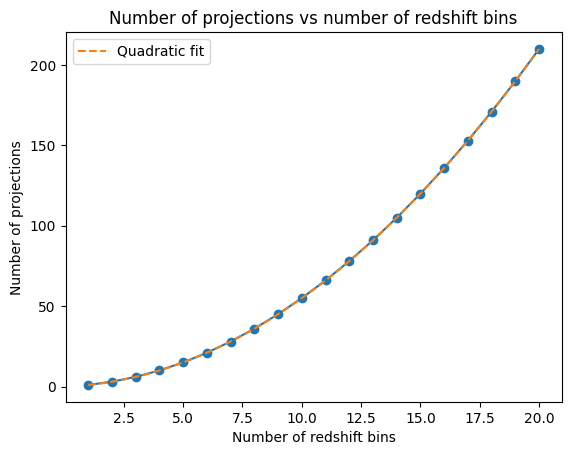

In [11]:
n_bins = np.linspace(1, 20, 20, dtype=int)

n_proj = np.empty_like(n_bins)
for i, n_bin in enumerate(n_bins):
    inds = list(zip(*np.tril_indices(n_bin)))
    n_proj[i] = len(inds)

plt.plot(n_bins, n_proj, marker='o')
plt.xlabel('Number of redshift bins')
plt.ylabel('Number of projections')
plt.title('Number of projections vs number of redshift bins')

popt = np.polyfit(n_bins, n_proj, deg=2)
x_fit = np.linspace(1, 20, 100)
y_fit = np.polyval(popt, x_fit)
plt.plot(x_fit, y_fit, label='Quadratic fit', ls='--')
plt.legend()

print(f"Quadratic fit coefficients: {popt}")

In [ ]:
# DES Y6
n_source = 4
n_lens = 6

# Cosmic shear
n_cosmic = len(list(zip(*np.tril_indices(n_source))))
print(f"Number of cosmic shear projections: {n_cosmic}")

# GGL, require lens in front of source
n_ggl = 

Number of cosmic shear projections: 10
Number of GGL projections: 6
